# Correlação entre variáveis numéricas e o target `dias_atraso`

**Target:** `dias_atraso = data_recebimento_provisorio - data_ordem_servico` (em dias)

Fluxo: carga → target → seleção de variáveis numéricas → correlações (Pearson e Spearman, com p-valor) → gráficos.

In [4]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Ajuste o caminho conforme o ambiente (ex.: /dbfs/FileStore/... no Databricks)
CAMINHO_CSV = "C:\\Users\\Gabriel\\OneDrive\\Documentos\\projeto_previsao_termino_obras\\data\\raw\\vw_modelagem_contratos_filtros.csv"

COL_INICIO = "data_ordem_servico"
COL_FIM = "data_recebimento_provisorio"
TARGET = "dias_atraso"

## 1. Carga dos dados

In [5]:
df = pd.read_csv(
    CAMINHO_CSV,
    na_values=["NULL", "", "ND", "Sem informação"],  # a view usa 'NULL' e 'ND' como texto
)
print(f"Shape: {df.shape}")
df.head()

Shape: (48, 50)


,idContrato,id_diretoria,id_setor_divisao,Instrumento_contratual,tipo_de_contrato,id_tipo_contrato,id_tipo_de_contrato,Classificacao_contrato,id_classificacao_contrato,id_predio,id_projeto_associado,id_Licitacao,id_fornecedor,email_fornecedor_contrato,numero_contrato,ano_contrato,NumeroContrato,Descricao,data_assinatura,prazo_total,valor_total_contrato,observacao_contrato,data_proposta,DataOrcamento,data_ordem_servico,data_ref_reajuste,data_conclusao,observacao_conclusao,processo_TRP,data_recebimento_provisorio,data_assinatura_TRP,processo_TRD,data_recebimento_TRD,data_assinatura_TRD,Informacoes_para_relatorio_proj,Flag_ativo_emissao_OS,Possui_etapas_projeto,Numero_etapas_projeto,Pauta_GEP,SEI_contrato,SEI_licitacao,Valor_licitado,Perc_desconto,Status_contrato,CT_paralisado,Data_paralisacao,Motivo_paralisacao,Data_previsao_retomada,CT_concluido,CT_rescindido
0,11,1,10,Contrato,Obra,3,3,Reforma Parcial,10,13,29,15,35,NaN,160,2018,160/2018,Reforma Parcial do Fórum de Concórdia - Substi...,2018-10-30,150,276770.81,Contrato em andamento,NaN,NaN,2019-07-24,NaN,2020-01-15,NaN,0087949-62.2019.8.24.0710,2020-01-15,2020-01-21,0018423-71.2020.8.24.0710,2020-04-23,2020-05-06,NaN,0,NaN,0,NaN,NaN,NaN,0.0,0.0,CONCLUÍDO,Não,NaN,NaN,NaN,Sim,Não
1,12,1,10,Contrato,Obra,3,3,Reforma Parcial,10,91,440,40,36,NaN,32,2018,32/2018,Reforma Parcial do Fórum de Laguna - PCI e PGDM,2018-02-28,90,123157.43,Contrato encerrado,2017-10-10,2016-07-01,2018-03-22,2016-07-01,2018-11-06,TRP emitido em 13/11/2018 no SPA n. 38656/2018,38656/2018,2018-11-06,2018-11-13,Sem inform.,2019-01-29,2019-01-31,NaN,0,NaN,0,NaN,NaN,NaN,0.0,0.0,CONCLUÍDO,Não,NaN,NaN,NaN,Sim,Não
2,18,1,10,Contrato,Obra,3,3,Reforma Parcial,10,75,34,33,39,NaN,145,2019,145/2019,Reforma Parcial do Fórum de Indaial - Cobertura,2019-08-19,120,286883.22,Sem observação,2019-05-30,2018-12-01,2019-09-11,2018-12-01,2020-02-08,NaN,0006733-45.2020.8.24.0710,2020-02-08,2020-04-16,0020034-59.2020.8.24.0710,2020-05-13,2020-05-18,NaN,0,NaN,0,NaN,NaN,NaN,0.0,0.0,CONCLUÍDO,Não,NaN,NaN,NaN,Sim,Não
3,29,1,10,Contrato,Obra,3,3,Reforma Parcial e Ampliação,12,14,15,20,41,NaN,210,2018,210/2018,Reforma e Ampliação do Fórum de Anchieta,2018-12-18,240,672041.16,Sem observação,2018-08-16,2018-01-01,2019-01-29,2018-01-01,2020-07-06,Considerada sem atraso: Cabe ressaltar que as ...,0012887-79.2020.8.24.0710,2020-07-06,2020-07-08,0012887-79.2020.8.24.0710,2020-10-19,2020-11-03,NaN,0,NaN,0,NaN,NaN,NaN,0.0,0.0,CONCLUÍDO,Não,NaN,NaN,NaN,Sim,Não
4,30,1,10,Contrato,Obra,3,3,Reforma Parcial,10,34,32,11,42,NaN,183,2019,183/2019,Instalação de rede de telecomunicações com red...,2019-11-19,90,393214.86,Sem observação,NaN,NaN,2020-01-07,NaN,2020-04-06,NaN,0018809-04.2020.8.24.0710,2020-04-06,2020-05-08,0024523-42.2020.8.24.0710,2020-07-06,2020-07-08,NaN,0,NaN,0,NaN,NaN,NaN,0.0,0.0,CONCLUÍDO,Não,NaN,NaN,NaN,Sim,Não


## 2. Construção do target

In [6]:
df[COL_INICIO] = pd.to_datetime(df[COL_INICIO], errors="coerce")
df[COL_FIM] = pd.to_datetime(df[COL_FIM], errors="coerce")

df[TARGET] = (df[COL_FIM] - df[COL_INICIO]).dt.days

print("Datas inválidas/nulas:", df[[COL_INICIO, COL_FIM]].isna().sum().to_dict())
print("Target negativo:", (df[TARGET] < 0).sum())
print("Target nulo:", df[TARGET].isna().sum())
df[TARGET].describe()

Datas inválidas/nulas: {'data_ordem_servico': 0, 'data_recebimento_provisorio': 0}
Target negativo: 0
Target nulo: 0


count      48.000000
mean      340.270833
std       274.979360
min        50.000000
25%       150.000000
50%       235.500000
75%       425.750000
max      1110.000000
Name: dias_atraso, dtype: float64

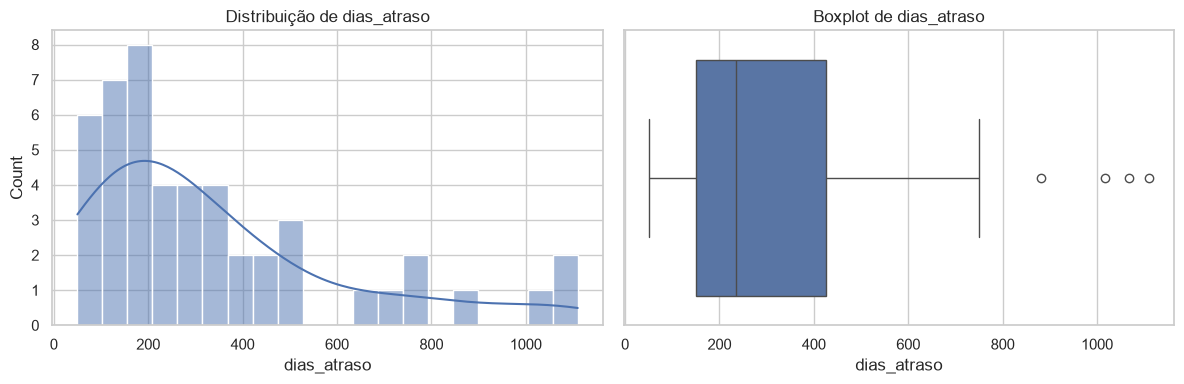

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET].dropna(), bins=20, kde=True, ax=axes[0])
axes[0].set_title("Distribuição de dias_atraso")
sns.boxplot(x=df[TARGET].dropna(), ax=axes[1])
axes[1].set_title("Boxplot de dias_atraso")
plt.tight_layout()
plt.show()

## 3. Seleção das variáveis numéricas

Saem da análise: identificadores (`id*`, `numero_contrato`), colunas 100% nulas, colunas constantes (sem variância não há correlação) e o próprio target.

In [8]:
num_cols = df.select_dtypes(include="number").columns.difference([TARGET])

padrao_id = re.compile(r"^id(_|[A-Z])|^numero_contrato$", flags=0)
ids = [c for c in num_cols if padrao_id.search(c)]
vazias = [c for c in num_cols if df[c].notna().sum() == 0]
constantes = [c for c in num_cols if df[c].nunique(dropna=True) <= 1 and c not in vazias]

excluir = set(ids) | set(vazias) | set(constantes)
features = [c for c in num_cols if c not in excluir]

print("Identificadores removidos:", ids)
print("100% nulas removidas:", vazias)
print("Constantes removidas:", constantes)
print("\nVariáveis analisadas:", features)
df[features].describe().T

Identificadores removidos: ['idContrato', 'id_Licitacao', 'id_classificacao_contrato', 'id_diretoria', 'id_fornecedor', 'id_predio', 'id_projeto_associado', 'id_setor_divisao', 'id_tipo_contrato', 'id_tipo_de_contrato', 'numero_contrato']
100% nulas removidas: ['Data_paralisacao', 'Data_previsao_retomada', 'Informacoes_para_relatorio_proj', 'Motivo_paralisacao', 'Pauta_GEP', 'Possui_etapas_projeto']
Constantes removidas: ['Numero_etapas_projeto', 'id_diretoria', 'id_tipo_contrato', 'id_tipo_de_contrato']

Variáveis analisadas: ['Flag_ativo_emissao_OS', 'Perc_desconto', 'Valor_licitado', 'ano_contrato', 'prazo_total', 'valor_total_contrato']


,count,mean,std,min,25%,50%,75%,max
Flag_ativo_emissao_OS,48.0,4.375000e-01,5.013280e-01,0.00,0.0000,0.00,1.000000e+00,1.00
Perc_desconto,48.0,3.457708e+00,7.132663e+00,0.00,0.0000,0.00,4.067500e+00,31.66
Valor_licitado,48.0,2.095040e+06,5.250004e+06,0.00,0.0000,0.00,9.629098e+05,26566948.92
ano_contrato,48.0,2.021146e+03,2.278387e+00,2018.00,2019.0000,2021.00,2.023000e+03,2025.00
prazo_total,48.0,2.300000e+02,2.135117e+02,60.00,90.0000,150.00,2.775000e+02,960.00
valor_total_contrato,48.0,2.687570e+06,5.020484e+06,74431.77,310031.1525,653749.77,1.742681e+06,19801812.59


## 4. Correlações com o target

In [10]:
!pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]




[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
def calcular_correlacoes(dados, features, target, min_obs=10):
    linhas = []
    for c in features:
        par = dados[[c, target]].dropna()
        if len(par) < min_obs or par[c].nunique() < 2:
            continue
        r_p, p_p = stats.pearsonr(par[c], par[target])
        r_s, p_s = stats.spearmanr(par[c], par[target])
        linhas.append({
            "variavel": c, "n": len(par),
            "pearson": r_p, "p_pearson": p_p,
            "spearman": r_s, "p_spearman": p_s,
        })
    res = pd.DataFrame(linhas)
    res["abs_spearman"] = res["spearman"].abs()
    res = res.sort_values("abs_spearman", ascending=False).drop(columns="abs_spearman")
    res["signif_5pct"] = (res["p_spearman"] < 0.05)
    return res.reset_index(drop=True)

corr = calcular_correlacoes(df, features, TARGET)
corr.style.format({
    "pearson": "{:.3f}", "spearman": "{:.3f}",
    "p_pearson": "{:.4f}", "p_spearman": "{:.4f}",
}).background_gradient(subset=["pearson", "spearman"], cmap="RdBu_r", vmin=-1, vmax=1)

,variavel,n,pearson,p_pearson,spearman,p_spearman,signif_5pct
0,prazo_total,48,0.908,0.0000,0.830,0.0000,True
1,valor_total_contrato,48,0.773,0.0000,0.750,0.0000,True
2,Valor_licitado,48,0.718,0.0000,0.312,0.0309,True
3,Perc_desconto,48,0.289,0.0467,0.163,0.2696,False
4,ano_contrato,48,-0.058,0.6954,-0.141,0.3376,False
5,Flag_ativo_emissao_OS,48,-0.133,0.3675,-0.120,0.4174,False


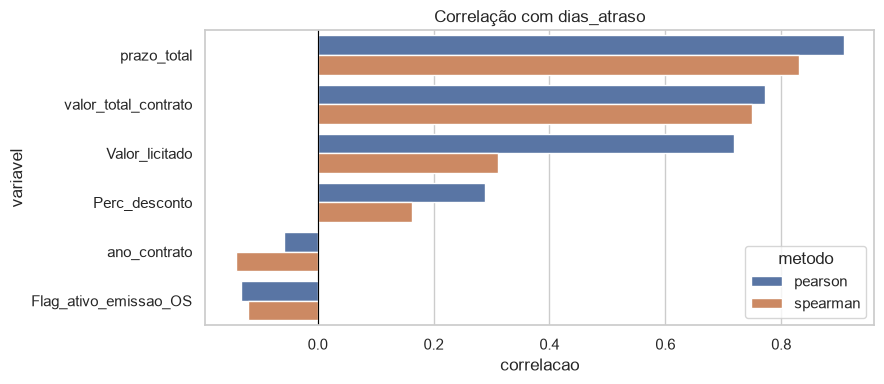

In [12]:
plot_df = corr.melt(id_vars="variavel", value_vars=["pearson", "spearman"],
                    var_name="metodo", value_name="correlacao")
ordem = corr["variavel"].tolist()

plt.figure(figsize=(9, max(4, 0.45 * len(ordem))))
sns.barplot(data=plot_df, y="variavel", x="correlacao", hue="metodo", order=ordem)
plt.axvline(0, color="black", lw=0.8)
plt.title(f"Correlação com {TARGET}")
plt.tight_layout()
plt.show()

## 5. Matriz de correlação (Spearman)

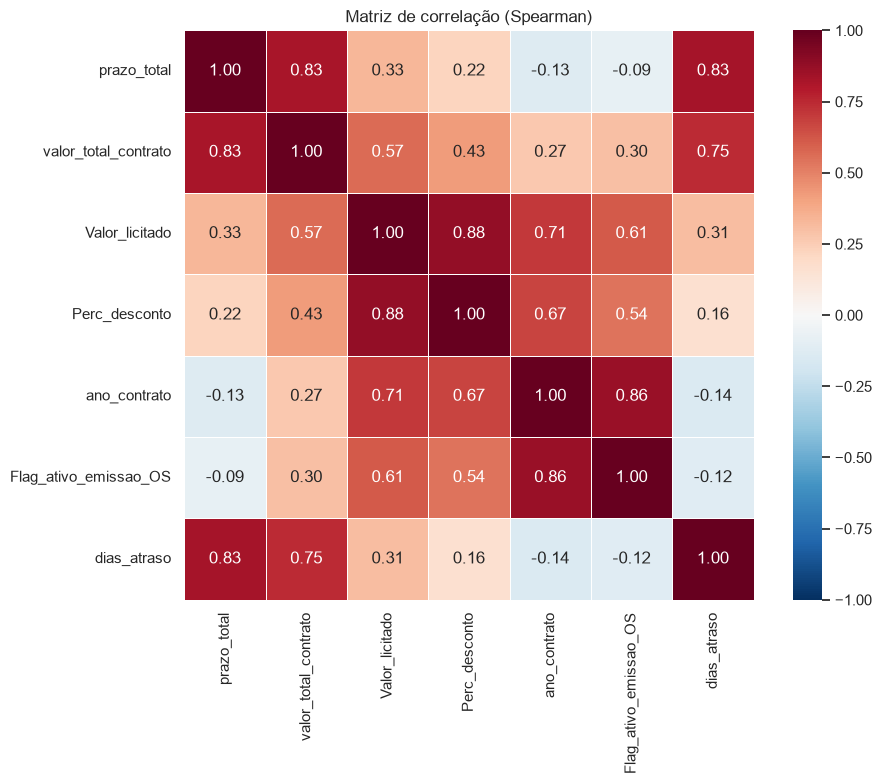

In [13]:
cols_matriz = corr["variavel"].tolist() + [TARGET]
matriz = df[cols_matriz].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Matriz de correlação (Spearman)")
plt.tight_layout()
plt.show()

## 6. Dispersão das variáveis mais correlacionadas

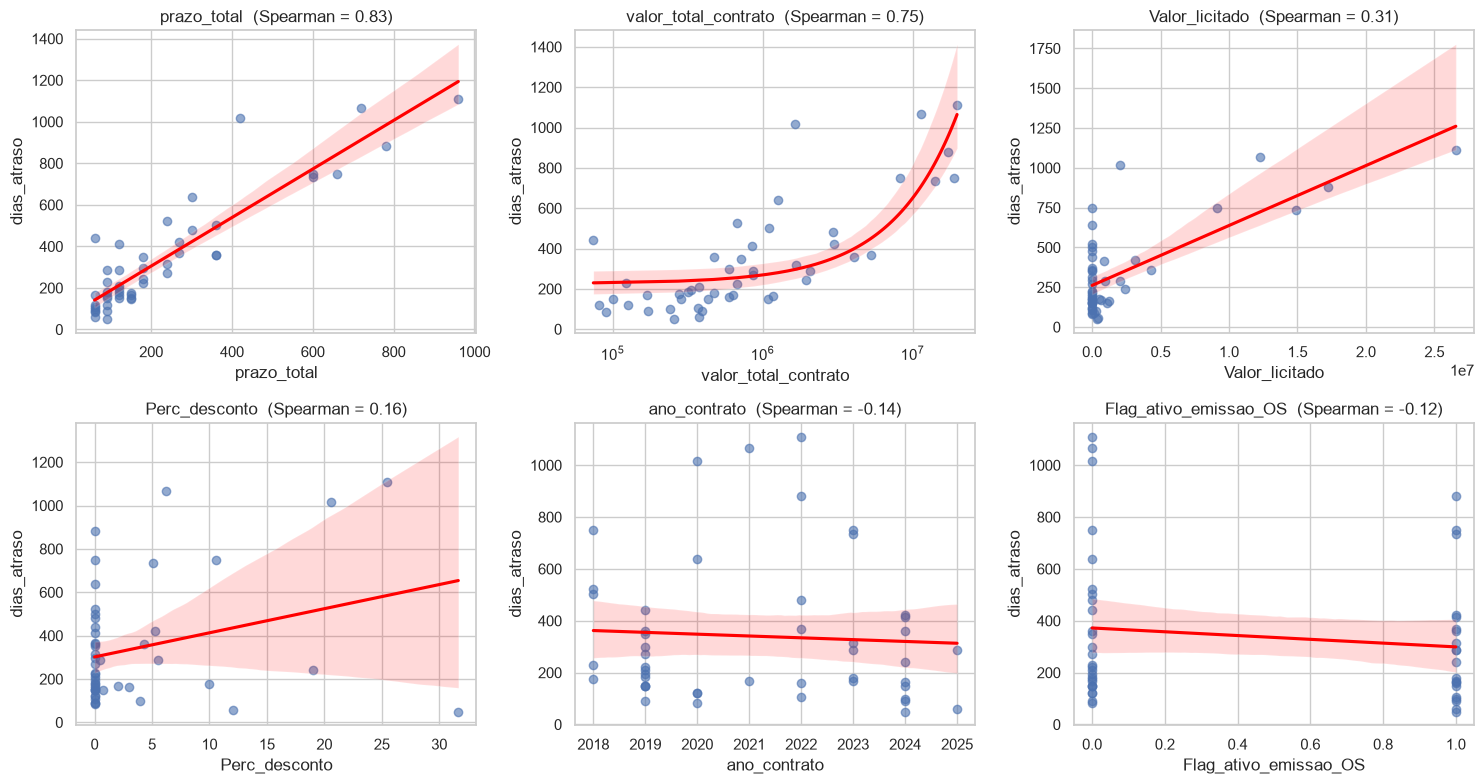

In [14]:
TOP_N = 6
top = corr.head(TOP_N)["variavel"].tolist()
ncols = 3
nrows = int(np.ceil(len(top) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
for ax, c in zip(np.array(axes).ravel(), top):
    sns.regplot(data=df, x=c, y=TARGET, ax=ax,
                scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
    r = corr.loc[corr["variavel"] == c, "spearman"].iloc[0]
    ax.set_title(f"{c}  (Spearman = {r:.2f})")
    if df[c].min() > 0 and df[c].max() / df[c].min() > 100:  # escala muito assimétrica
        ax.set_xscale("log")
for ax in np.array(axes).ravel()[len(top):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. (Opcional) Atraso real em relação ao prazo contratual

O target pedido (`recebimento_provisorio - ordem_servico`) é, na prática, a **duração real da execução**.
Por isso ele tende a ter correlação muito alta com `prazo_total`. Para medir o atraso de fato, compare a duração
com o prazo contratado: `atraso_vs_prazo = dias_atraso - prazo_total` (positivo = estourou o prazo).

In [15]:
TARGET_ALT = "atraso_vs_prazo"
df[TARGET_ALT] = df[TARGET] - df["prazo_total"]

print(df[TARGET_ALT].describe())
print(f"\nContratos acima do prazo: {(df[TARGET_ALT] > 0).sum()} de {df[TARGET_ALT].notna().sum()}")

features_alt = [c for c in features if c != "prazo_total"]  # prazo_total entra na definição do target alternativo
corr_alt = calcular_correlacoes(df, features_alt, TARGET_ALT)
corr_alt

count     48.000000
mean     110.270833
std      120.902764
min      -40.000000
25%       30.000000
50%       75.500000
75%      150.000000
max      597.000000
Name: atraso_vs_prazo, dtype: float64

Contratos acima do prazo: 41 de 48


,variavel,n,pearson,p_pearson,spearman,p_spearman,signif_5pct
0,valor_total_contrato,48,0.146642,0.319942,0.427656,0.002430,True
1,Valor_licitado,48,0.168299,0.252850,0.163417,0.267074,False
2,Flag_ativo_emissao_OS,48,-0.207700,0.156612,-0.127404,0.388170,False
3,ano_contrato,48,-0.118786,0.421320,-0.086353,0.559495,False
4,Perc_desconto,48,0.131716,0.372180,0.052751,0.721778,False


## Pontos de atenção

- **Amostra pequena** (poucas dezenas de contratos): olhe os p-valores e não só o coeficiente.
- **Spearman** é mais robusto que Pearson para `valor_total_contrato` e `Valor_licitado` (muito assimétricos, com outliers).
- `Valor_licitado` e `Perc_desconto` têm muitos zeros, que podem representar ausência de licitação/dado e não valor zero; considere tratá-los como nulo.
- Correlação não implica causalidade, e `prazo_total` e `valor_total_contrato` são correlacionados entre si (multicolinearidade).